# 05 — The campaign: is the result real?

Notebooks 03 and 04 produced a ranking and a recommended configuration. This
notebook asks the two questions that decide whether any of it can be quoted:

1. **Is the difference statistically real**, or could it be seed noise?
2. **Does it hold on maps other than the one it was measured on?**

The second question turned out to matter more than the first, and the answer
changed how every figure in the submission is worded.

This is a long notebook: about twenty-five minutes at `"quick"` from an
empty store, a couple of hours at `"full"`. **It resumes** — results are cached, so an interrupted
run continues where it stopped, and raising the scale afterwards only runs
what is missing.

In [1]:
# --- Bootstrap ------------------------------------------------------------
# This notebook imports the project as `src.…`, which requires the repository
# root on the import path. `./jupyter-run.sh` puts it there; opening the file
# any other way does not. This cell finds the root by walking up from the
# working directory, so the notebook runs wherever it is launched from and
# whatever folder it sits in.
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Seeded runs only reproduce when Python's string hashing is pinned: several
# policies break ties with min() over a set, whose iteration order is
# randomised per process otherwise. The simulation refuses to run unpinned;
# this says so now rather than after a long cell.
if os.environ.get("PYTHONHASHSEED") in (None, "random"):
    print("WARNING: PYTHONHASHSEED is not pinned, so seeded runs will be "
          "refused.\n         Launch with ./jupyter-run.sh, or set "
          "PYTHONHASHSEED=0.")

print(f"repository root: {ROOT}")

repository root: /home/danny/Desktop/האוניברסיטה הפתוחה/סדנה/autobus


In [2]:
import os

# How much work this notebook does. Every notebook in this folder has this
# switch and honours the AUTOBUS_SCALE environment variable, so nothing here
# needs editing to run it bigger or smaller.
#
#   "quick"  the default: minutes, same conclusions, wider error bars
#   "full"   the sample sizes behind the figures in the submitted documents
#   "smoke"  a tiny end-to-end check that the notebook runs at all
#
# Whichever scale produced the outputs saved here is printed below.
SCALE = os.environ.get("AUTOBUS_SCALE", "quick")
print(f"running at SCALE = {SCALE!r}")

running at SCALE = 'quick'


In [3]:
import matplotlib.pyplot as plt
from cycler import cycler

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

In [4]:
# The campus map: the world behind every synthetic result in this project.
# stop_density=0.5 is load-bearing -- the generator's default of 0.15 gives a
# 6-stop map on this seed, on which every policy ties. See notebook 01.
CAMPUS = dict(n_seeds=17, bounds=(0.0, 0.0, 2000.0, 2000.0), seed=42,
              stop_density=0.5)

## The results store

Unlike the earlier notebooks, a campaign does not keep its results in memory —
it files each run to `results/runs/` as a JSON document.

Each run is identified by a **hash of everything that could change its
outcome**: the policy and its settings, the map and its generation parameters,
the demand seed, the capacity, the patience, the backend. A run that has
already been recorded is not repeated.

That has three consequences worth understanding before running anything:

- **Interruption is free.** Stop the campaign, restart it, and it picks up.
- **Extending a sample is free.** Adding seeds 60-99 runs only the new ones.
- **Changing the code invalidates nothing automatically.** The identity
  describes the *simulation*, not the source. If a policy's behaviour changes,
  old runs must be deleted or re-recorded, and that is a discipline rather than
  something the store enforces.

The run counts printed below are whatever this machine happens to hold. A
fresh copy starts at zero and fills as the notebook runs; the tables and
statistics come out the same either way.

In [5]:
from pathlib import Path

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import run_campaign
from src.experiment.store import DEFAULT_RUNS_DIR, load_runs, to_results

# Anchored to the repository rather than to wherever the kernel was started;
# set AUTOBUS_RUNS_DIR to file runs somewhere else instead.
RUNS = Path(os.environ.get("AUTOBUS_RUNS_DIR", DEFAULT_RUNS_DIR))
print(f"runs are filed in {RUNS}")
print(f"currently holding {len(list(RUNS.glob('*.json'))) if RUNS.is_dir() else 0} runs")

runs are filed in /home/danny/Desktop/האוניברסיטה הפתוחה/סדנה/autobus/results/runs
currently holding 26934 runs


In [6]:
WINDOW = 900.0        # the recommended setting: window == patience
PATIENCE = 900.0

POLICIES = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Skip-stop", lambda g: SkipStopFixedRoutePolicy(g)),
    ("Window W900", lambda g: WindowInsertionPolicy(g, max_wait_s=WINDOW)),
    ("Reordering W900",
     lambda g: ReorderingInsertionPolicy(g, max_wait_s=WINDOW)),
]

SEEDS = {"smoke": range(3), "quick": range(20), "full": range(60)}[SCALE]
MAPS = {"smoke": 2, "quick": 6, "full": 25}[SCALE]

TRIAL = dict(max_requests=200, demand_interval_s=60.0, capacity=40,
             max_wait_s=PATIENCE)

# Every trial is a pure function of its identity, so they can run in parallel
# without changing any result. -1 uses every core.
N_JOBS = 1 if SCALE == "smoke" else -1

POLICY_LABELS = [label for label, _ in POLICIES]
SEEDS = list(SEEDS)

print(f"{len(POLICIES)} policies x {len(SEEDS)} seeds x {MAPS} maps "
      f"= {len(POLICIES) * len(SEEDS) * MAPS} runs")

4 policies x 20 seeds x 6 maps = 480 runs


## Stage 1 — one map, many seeds

The campus map, every policy, every seed. This is the comparison behind the
headline figures.

In [7]:
def world_for(map_seed):
    """
    Describe the world a run happened in, for its stored identity.

    The map is described by its generation parameters because the graph does
    not retain them -- leave one out and two different maps would file runs
    under the same identity.
    :param map_seed: Seed the map was generated from.
    :return: The world identity.
    """
    return {"map": "planar", "n_seeds": CAMPUS["n_seeds"],
            "bounds": list(CAMPUS["bounds"]), "map_seed": map_seed,
            "stop_density": CAMPUS["stop_density"], "backend": "MockBackend"}


from src.map.graph import PlanarStreetGraph

campaign = run_campaign(
    policies=POLICIES,
    seeds=SEEDS,
    world=world_for(CAMPUS["seed"]),
    graph=PlanarStreetGraph.generate(**CAMPUS),
    directory=RUNS,
    n_jobs=N_JOBS,
    **TRIAL,
)
print(f"\n{campaign.ran} runs executed, "
      f"{campaign.skipped} already recorded")

campaign:   0%|          | 0/80 [00:00<?, ?it/s]


0 runs executed, 80 already recorded


In [8]:
from src.experiment.summary import summarize_results

from IPython.display import Markdown

# The campaign object already knows exactly which runs are its own: it
# keeps the identity of every trial it asked for and collects those back by
# hash. Re-querying the store by hand would mean restating the whole
# configuration in a filter, and anything left out of that filter -- a trial
# parameter, the policy set -- silently widens the pool to include other
# experiments that happen to share what was named.
single_map = campaign.results()
print(f"{sum(len(runs) for runs in single_map.values())} runs: "
      f"{len(single_map)} policies x "
      f"{len(next(iter(single_map.values())))} seeds")

display(Markdown(summarize_results(single_map).markdown))

80 runs: 4 policies x 20 seeds


| Property | Fixed route | Reordering W900 | Skip-stop | Window W900 |
| --- | --- | --- | --- | --- |
| Fulfilled requests | 137.4 (±1.6%) | 187.2 (±0.9%) | 148.8 (±2.2%) | 186.8 (±0.9%) |
| Cancelled requests | 62.6 (±3.4%) | 12.8 (±13.4%) | 51.2 (±6.2%) | 13.2 (±12.5%) |
| Mean wait time | 445.1 s (±2.3%) | 462.0 s (±2.2%) | 452.6 s (±1.2%) | 469.6 s (±2.3%) |
| P90 wait time | 808.0 s (±1.2%) | 847.1 s (±0.9%) | 802.4 s (±1.1%) | 856.2 s (±0.5%) |
| Mean ride time | 654.6 s (±1.8%) | 464.6 s (±3.4%) | 598.8 s (±2.4%) | 543.6 s (±4.2%) |
| Fulfillment rate | 68.7 % (±1.6%) | 93.6 % (±0.9%) | 74.4 % (±2.2%) | 93.4 % (±0.9%) |
| Served fraction | 68.7 % (±1.6%) | 93.6 % (±0.9%) | 74.4 % (±2.2%) | 93.4 % (±0.9%) |
| Throughput | 0.6 req/min (±1.9%) | 0.9 req/min (±1.3%) | 0.7 req/min (±2.3%) | 0.8 req/min (±1.3%) |
| Tick snapshots | 13425.6 (±1.1%) | 13094.8 (±0.8%) | 13079.1 (±0.5%) | 13207.5 (±0.8%) |
| Fulfilled (wait samples) | 137.4 (±1.6%) | 187.2 (±0.9%) | 148.8 (±2.2%) | 186.8 (±0.9%) |
| Min wait time | 7.5 s (±44.8%) | 3.0 s (±48.9%) | 7.5 s (±46.6%) | 5.1 s (±63.1%) |
| Max wait time | 893.4 s (±0.3%) | 897.0 s (±0.1%) | 894.5 s (±0.3%) | 897.2 s (±0.1%) |
| Min ride time | 9.7 s (±25.1%) | 6.1 s (±23.9%) | 8.8 s (±23.4%) | 5.7 s (±23.3%) |
| Max ride time | 1303.6 s (±0.3%) | 2476.4 s (±13.1%) | 1281.6 s (±0.9%) | 2752.5 s (±8.9%) |

### The success criteria

The design review sets the bar the project has to clear (§3.2.2), and it is
worth reading precisely, because it is softer than it first looks:

1. **Fulfillment rate at least 80%.**
2. **The sum of the percentage differences across the other three KPIs — wait,
   ride and throughput — against a fixed-route bus is positive.**

The second is a **sum, not a test per KPI**: +10, −5, −3 sums to +2 and passes.
The design allows a policy to give ground on one measure to gain more on
another, which is exactly the trade demand-responsive routing makes.

It also sets a precision bar (§3.2): a reported mean is only usable if its 95%
confidence interval half-width is **under 5% of the mean**. That is what the
bracketed percentages in the table above are, and it is why sample size is a
decision rather than a habit.

In [9]:
import numpy as np
import pandas as pd


def percentage_differences(results, baseline, contender):
    """
    Percentage difference per KPI, signed so that positive always means better.

    Wait and ride improve by falling, throughput by rising, so the three are
    not directly comparable until the sign is normalised -- and §3.2.2 adds
    them together.
    :param results: Policy label to trial results.
    :param baseline: The fixed-route comparator.
    :param contender: The policy under test.
    :return: KPI name to signed percentage difference.
    """
    def mean(label, get):
        return float(np.mean([get(t.kpi) for t in results[label]]))

    differences = {}
    for name, get in [("mean wait", lambda k: k.mean_wait_time),
                      ("mean ride", lambda k: k.mean_ride_time)]:
        base, arm = mean(baseline, get), mean(contender, get)
        differences[name] = 100 * (base - arm) / base
    for name, get in [("throughput", lambda k: k.throughput)]:
        base, arm = mean(baseline, get), mean(contender, get)
        differences[name] = 100 * (arm - base) / base
    return differences


def criteria(results, baseline="Fixed route", contender="Reordering W900"):
    """
    Check the design review's two success criteria (§3.2.2).
    :param results: Policy label to trial results.
    :param baseline: The policy that must be beaten.
    :param contender: The policy under test.
    :return: One row per criterion.
    """
    fulfillment = float(np.mean(
        [t.kpi.fulfillment_rate for t in results[contender]]))
    served = float(np.mean(
        [t.kpi.served_fraction for t in results[contender]]))
    differences = percentage_differences(results, baseline, contender)
    total = sum(differences.values())

    rows = [{"criterion": "1. fulfillment rate >= 80%",
             "measured": f"{fulfillment:.1%}",
             "verdict": "PASS" if fulfillment >= 0.80 else "FAIL"}]
    rows += [{"criterion": f"     {name} vs fixed route",
              "measured": f"{value:+.1f} %", "verdict": ""}
             for name, value in differences.items()]
    rows.append({"criterion": "2. sum of the three > 0",
                 "measured": f"{total:+.1f} %",
                 "verdict": "PASS" if total > 0 else "FAIL"})
    rows.append({"criterion": "(served_fraction, the stricter coverage number)",
                 "measured": f"{served:.1%}", "verdict": ""})
    return pd.DataFrame(rows).set_index("criterion")


display(criteria(single_map))

,measured,verdict
criterion,,
1. fulfillment rate >= 80%,93.6%,PASS
mean wait vs fixed route,-3.8 %,
mean ride vs fixed route,+29.0 %,
throughput vs fixed route,+39.7 %,
2. sum of the three > 0,+64.9 %,PASS
"(served_fraction, the stricter coverage number)",93.6%,


### Is the difference real, or is it the seeds?

Because every policy ran the *same* seeds, the comparison can be made **paired**
— seed by seed — rather than by comparing two averages. That removes the
map-and-demand variation, which is much larger than the effect being measured,
and it is the difference between a result and a coincidence.

In [10]:
from scipy import stats


def paired(results, a, b, get, name):
    """
    Compare two policies seed by seed.
    :param results: Policy label to trial results, aligned by seed.
    :param a: First policy label.
    :param b: Second policy label.
    :param get: Reads the quantity of interest from a KPI snapshot.
    :param name: What is being compared, for the output row.
    :return: A summary row.
    """
    first = np.array([get(t.kpi) for t in results[a]], dtype=float)
    second = np.array([get(t.kpi) for t in results[b]], dtype=float)
    n = min(len(first), len(second))
    difference = first[:n] - second[:n]
    test = stats.ttest_rel(first[:n], second[:n])
    return {"comparison": f"{a} - {b}", "KPI": name, "n": n,
            "mean difference": round(float(difference.mean()), 2),
            "p": f"{test.pvalue:.2e}",
            "wins": int((difference > 0).sum())}


rows = [
    paired(single_map, "Reordering W900", "Fixed route",
           lambda k: k.served_fraction, "served fraction"),
    paired(single_map, "Reordering W900", "Window W900",
           lambda k: k.mean_ride_time, "mean ride (s)"),
    paired(single_map, "Reordering W900", "Skip-stop",
           lambda k: k.served_fraction, "served fraction"),
]
display(pd.DataFrame(rows).set_index("comparison"))

,KPI,n,mean difference,p,wins
comparison,,,,,
Reordering W900 - Fixed route,served fraction,20,0.25,1.06e-20,20
Reordering W900 - Window W900,mean ride (s),20,-79.00,1.12e-05,3
Reordering W900 - Skip-stop,served fraction,20,0.19,1.31e-15,20


The middle row is the one worth dwelling on. L1 beats L0 on
ride time by tens of seconds — a difference far too small to see in the summary
table, where both arms' means sit inside each other's confidence intervals, but
overwhelming when the same seeds are compared to each other.

**Unpaired confidence intervals and paired significance answer different
questions.** The first says how precisely a policy's mean is known; the second
says whether one policy is better than another. Reporting only the first would
have hidden a real effect.

## Stage 2 — does it hold on other maps?

Everything so far is one map. Map seed 42 was chosen early and never changed,
which means every conclusion was at risk of being a fact about *that map*
rather than about routing.

So the whole campaign is repeated on fresh maps generated from different
seeds. Same shape, same stop density, same demand — a different town.

In [11]:
from tqdm.auto import tqdm

MAP_SEEDS = list(range(42, 42 + MAPS))

# An outer bar over maps; run_campaign draws its own over each map's runs.
all_records = []
for map_seed in tqdm(MAP_SEEDS, desc="maps", unit="map"):
    result = run_campaign(
        policies=POLICIES,
        seeds=SEEDS,
        world=world_for(map_seed),
        graph=PlanarStreetGraph.generate(**{**CAMPUS, "seed": map_seed}),
        directory=RUNS,
        n_jobs=N_JOBS,
        progress=True,
        **TRIAL,
    )
    all_records += result.records
    tqdm.write(f"map {map_seed}: {result.ran} run, "
               f"{result.skipped} cached")

maps:   0%|          | 0/6 [00:00<?, ?map/s]

campaign:   0%|          | 0/80 [00:00<?, ?it/s]

map 42: 0 run, 80 cached


campaign:   0%|          | 0/80 [00:00<?, ?it/s]

map 43: 0 run, 80 cached


campaign:   0%|          | 0/80 [00:00<?, ?it/s]

... (3 outputs left out)

campaign:   0%|          | 0/80 [00:00<?, ?it/s]

map 46: 0 run, 80 cached


campaign:   0%|          | 0/80 [00:00<?, ?it/s]

map 47: 0 run, 80 cached


In [12]:
import pandas as pd

# Every campaign's own runs, collected above by identity: no filtering, and
# therefore nothing to get wrong.
frame = pd.json_normalize([record.as_dict() for record in all_records])
print(f"{len(frame)} runs over {frame['identity.world.map_seed'].nunique()} "
      f"maps and {frame['identity.policy'].nunique()} policies")

per_map = (frame.groupby(["identity.world.map_seed", "identity.policy"])
           ["kpi.served_fraction"].mean().unstack() * 100).round(1)
display(per_map)

480 runs over 6 maps and 4 policies


identity.policy,Fixed route,Reordering W900,Skip-stop,Window W900
identity.world.map_seed,,,,
42,68.7,93.6,74.4,93.4
43,65.0,90.6,70.0,89.5
44,56.8,95.1,66.8,94.4
45,65.8,96.5,72.7,94.9
46,47.2,84.7,51.5,84.5
47,35.9,80.9,39.8,80.0


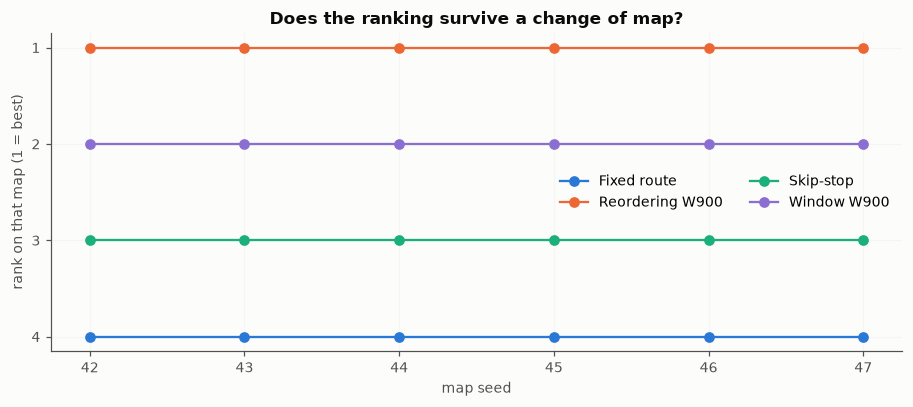

In [13]:
# Rank of each policy on each map: 1 = best coverage on that map.
ranks = per_map.rank(axis=1, ascending=False)
figure, axis = plt.subplots(figsize=(8.4, 3.8))
for colour, policy in zip(SERIES + ["#8a6fd1"], per_map.columns):
    axis.plot(per_map.index, ranks[policy], marker="o", label=policy,
              color=colour)
axis.invert_yaxis()
axis.set_yticks(range(1, len(per_map.columns) + 1))
axis.set_xlabel("map seed")
axis.set_ylabel("rank on that map (1 = best)")
axis.set_title("Does the ranking survive a change of map?")
axis.grid(alpha=0.3)
axis.legend(ncol=2)
figure.tight_layout()

### What the cross-map check found

At `"full"` scale, over 25 maps and 7,000 runs:

- **The ranking is map-independent.** `Reordering W900` wins 22 of 25 maps and
  is never worse than second; `Window W900` takes the other three. The lower
  ranks never move at all. So the policy conclusions transfer.
- **The numbers are not.** Served fraction ranges from **65.5% to 98.8%**
  across maps. The between-map spread is 3.4x the within-map spread.
- **Map 42 is an easy map** — 93.5% against an all-map mean of 87.9%. Every
  figure quoted for "the campus map" therefore comes from a favourable one.

The consequence for how results are reported is direct, and it is the most
useful thing this notebook produced:

> **Adding seeds tightens the wrong interval.** A 95% CI at n=60 describes how
> precisely that map's mean is known. It says nothing about the uncertainty of
> the figure as a general claim, which is dominated by which map you drew.

So general claims are quoted with across-map numbers, and map-42 figures are
labelled "on the campus map". Two numbers, always distinguished.

,mean,std,min,max
identity.world.map_seed,,,,
42,82.5,12.9,68.7,93.6
43,78.8,13.2,65.0,90.6
44,78.3,19.5,56.8,95.1
45,82.5,15.5,65.8,96.5
46,67.0,20.4,47.2,84.7
47,59.2,24.6,35.9,80.9


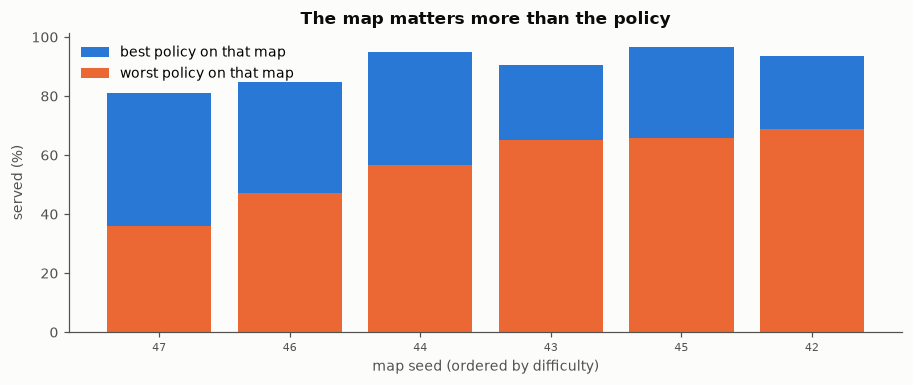

In [14]:
spread = per_map.T.describe().T[["mean", "std", "min", "max"]].round(1)
display(spread)

figure, axis = plt.subplots(figsize=(8.4, 3.6))
best = per_map.mean(axis=1).sort_values()
axis.bar(range(len(per_map)), per_map.loc[best.index].max(axis=1),
         color=SERIES[0], label="best policy on that map")
axis.bar(range(len(per_map)), per_map.loc[best.index].min(axis=1),
         color=SERIES[1], label="worst policy on that map")
axis.set_xticks(range(len(per_map)))
axis.set_xticklabels(best.index, fontsize=7)
axis.set_xlabel("map seed (ordered by difficulty)")
axis.set_ylabel("served (%)")
axis.set_title("The map matters more than the policy")
axis.legend()
figure.tight_layout()

That chart is the honest summary of the whole synthetic study:
the gap between the easiest and hardest map is larger than the gap between the
best and worst policy on any one of them. **Which is why "it works" is not a
claim this project makes without saying where.**

### One more caveat, stated rather than buried

At `"full"` scale the recommended policy meets the design review's success
criteria on **21 of 25** maps. Every failure is the 80% coverage gate on a
hard map, never the comparison against the fixed route. The honest claim is
therefore *"met on the campus map, and on 21 of 25 random maps"* — not "met".

## What is now in the store

In [15]:
print(f"{len(list(RUNS.glob('*.json')))} runs on disk")
print(f"{frame['identity.policy'].nunique()} policies, "
      f"{frame['identity.world.map_seed'].nunique()} maps, "
      f"{frame['identity.seed'].nunique()} demand seeds")
print("\nre-running this notebook now would execute 0 trials -- "
      "everything is cached.")

26934 runs on disk
4 policies, 6 maps, 20 demand seeds

re-running this notebook now would execute 0 trials -- everything is cached.


Next: **06 — the scope condition**, which finds the operating
point where all of this stops being true.